In [2]:
#import necessary libraries

import warnings 
warnings.filterwarnings('ignore')


import pandas as pd
import numpy as np


import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

from sklearn.linear_model import LogisticRegression

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score

sns.set(style='white', context='notebook')


In [3]:
df = pd.read_csv('adult.csv')
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.581647,13.640433,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.366512,105549.977697,12285.0,117827.0,178356.0,237051.0,1484705.0
education.num,32561.0,10.080679,2.572720,1.0,9.0,10.0,12.0,16.0
capital.gain,32561.0,1077.648844,7385.292085,0.0,0.0,0.0,0.0,99999.0
capital.loss,32561.0,87.303830,402.960219,0.0,0.0,0.0,0.0,4356.0
hours.per.week,32561.0,40.437456,12.347429,1.0,40.0,40.0,45.0,99.0


In [6]:
#replace '?' with NaN values
df[df == '?'] = np.nan
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       30725 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      30718 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 
 13  native.country  31978 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


In [7]:
#fill missing values with the mode of the respective columns
for col in ['workclass', 'occupation', 'native.country']:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [8]:
#make a copy of the original data
copy1 = df.copy()

## Exploratory Data Analysis

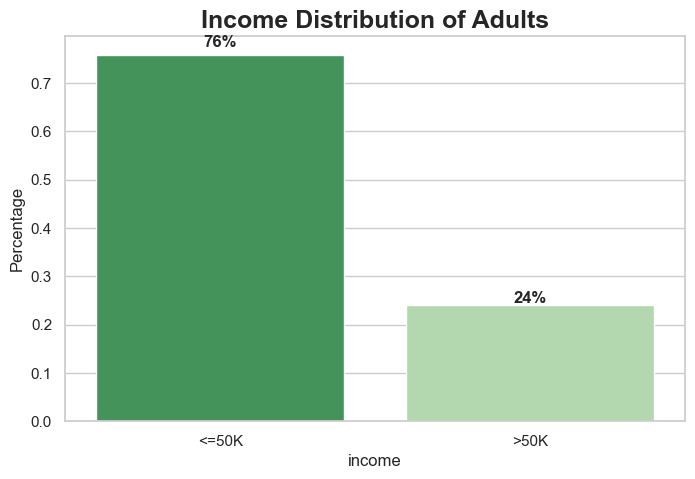

In [9]:
#Income distribution of adults

sns.set_style("whitegrid")
plt.figure(figsize = (8,5))
plt.title('Income Distribution of Adults', fontsize=18, fontweight='bold')
eda_percentage = df['income'].value_counts(normalize = True).rename_axis('income').reset_index(name = 'Percentage')

ax = sns.barplot(x = 'income', y = 'Percentage', data = eda_percentage.head(10), palette='Greens_r')
for p in ax.patches:
    width = p.get_width()
    height = p.get_height()
    x, y = p.get_xy() 
    ax.annotate(f'{height:.0%}', (x + width/2, y + height*1.02), ha='center', fontweight='bold')

In [10]:
# Create age groups 

def age_group(x):
    x = int(x)
    x = abs(x)
    if( 18 < x < 31 ):
        return "19-30"
    if( 30 < x < 41 ):
        return "31-40"
    if( 40 < x < 51 ):
        return "41-50"
    if( 50 < x < 61 ):
        return "51-60"
    if( 60 < x < 71 ):
        return "61-70"
    else:
        return "Greater than 70"

df['age_group'] = df['age'].apply(age_group)

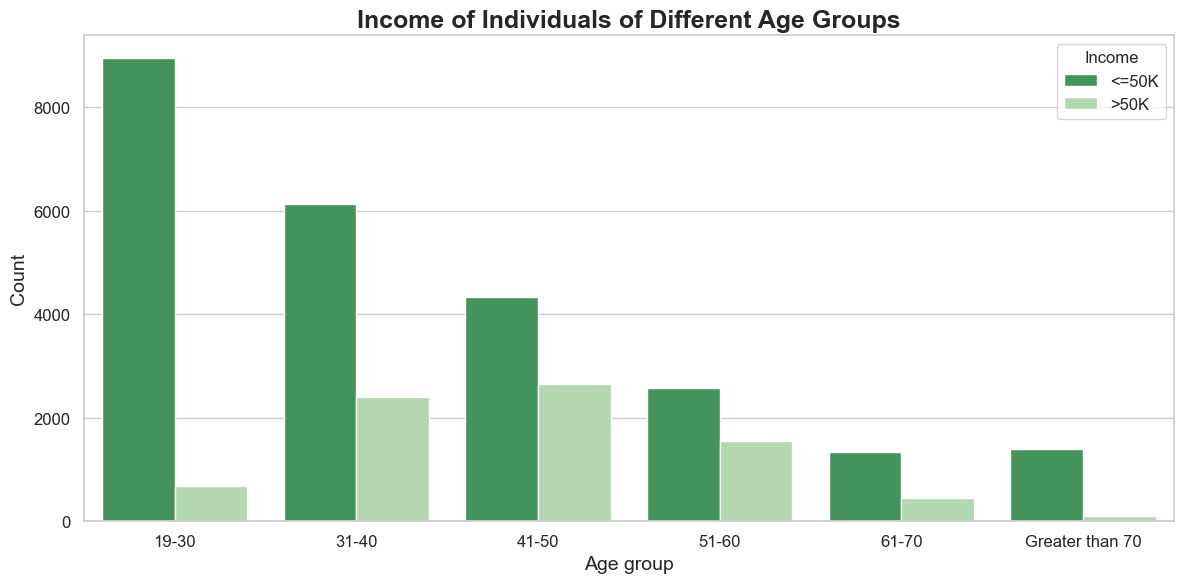

In [ ]:
#income distribution across different age groups

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

order_list = ['19-30', '31-40', '41-50', '51-60', '61-70', 'Greater than 70']
df['age_group'] = pd.Categorical(df['age_group'], categories=order_list, ordered=True)

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x='age_group',
    hue='income',              
    order=order_list,
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Age Groups', fontsize=18, fontweight='bold')
plt.xlabel('Age group', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)
plt.legend(title='Income', fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()


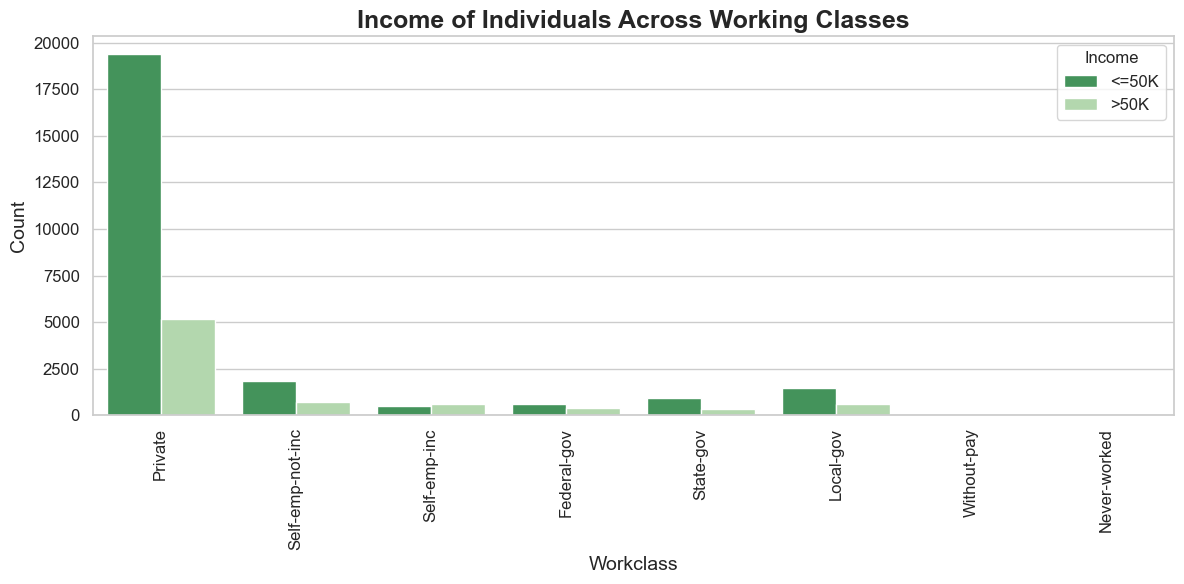

In [ ]:
#income distribution across different workclasses

for c in ["workclass", "income"]:
    if c in df.columns and df[c].dtype == object:
        df[c] = df[c].str.strip()

new_data = ["Private","Self-emp-not-inc","Self-emp-inc","Federal-gov",
           "State-gov","Local-gov","Without-pay","Never-worked"]
order_workclass = [w for w in new_data if w in df["workclass"].unique()]


plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x="workclass",
    hue="income",
    order=order_workclass if len(order_workclass)>0 else None,
    hue_order=["<=50K", ">50K"],    
    palette="Greens_r"
)
plt.title("Income of Individuals Across Working Classes", fontsize=18, fontweight="bold")
plt.xlabel("Workclass", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks(fontsize=12, rotation=90)
plt.yticks(fontsize=12)
plt.legend(title="Income", fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()


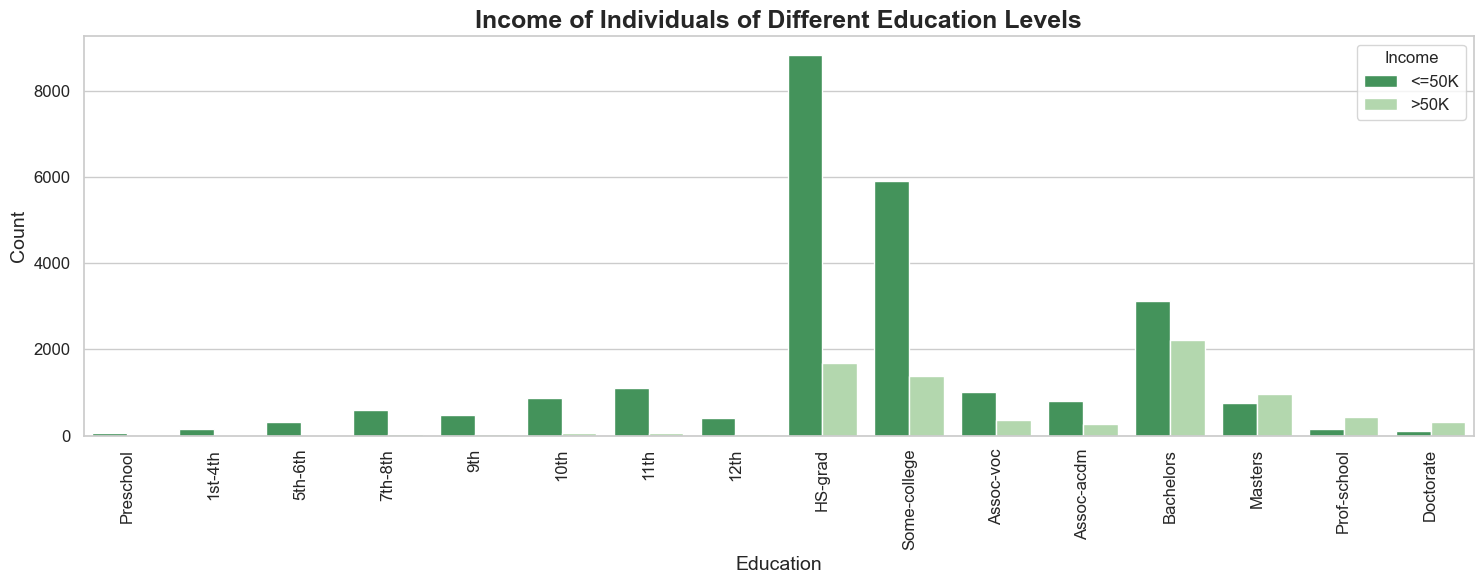

In [ ]:
#income distribution across different education levels

df['education'] = df['education'].astype(str).str.strip()
df['income']    = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

educ_order = [
    'Preschool','1st-4th','5th-6th','7th-8th','9th','10th','11th','12th',
    'HS-grad','Some-college','Assoc-voc','Assoc-acdm','Bachelors','Masters','Prof-school','Doctorate'
]

present_order = [e for e in educ_order if e in df['education'].unique()]
df['education'] = pd.Categorical(df['education'], categories=present_order, ordered=True)

plt.figure(figsize=(15,6))
sns.countplot(
    data=df,
    x='education',
    hue='income',                         
    order=present_order,
    hue_order=['<=50K', '>50K'],          
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Education Levels', fontsize=18, fontweight='bold')
plt.xlabel('Education', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12, rotation=90)
plt.yticks(fontsize=12)
plt.legend(title='Income', fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()

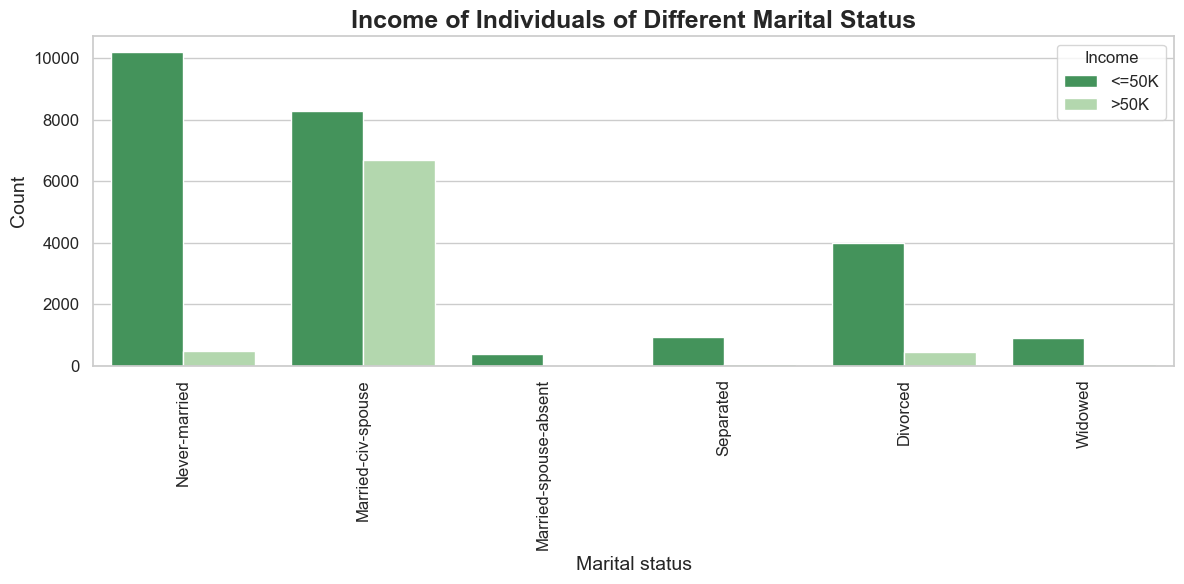

In [14]:
#income distribution across different marital status

col = 'marital-status' if 'marital-status' in df.columns else 'marital.status'

df[col] = df[col].astype(str).str.strip()
df['income'] = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

desired = ['Never-married','Married-civ-spouse','Married-spouse-absent',
           'Separated','Divorced','Widowed']
order_present = [m for m in desired if m in df[col].unique()]

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x=col,
    hue='income',
    order=order_present if order_present else None,
    hue_order=['<=50K','>50K'],
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Marital Status', fontsize=18, fontweight='bold')
plt.xlabel('Marital status', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(fontsize=12, rotation=90)
plt.yticks(fontsize=12)
plt.legend(title='Income', fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()

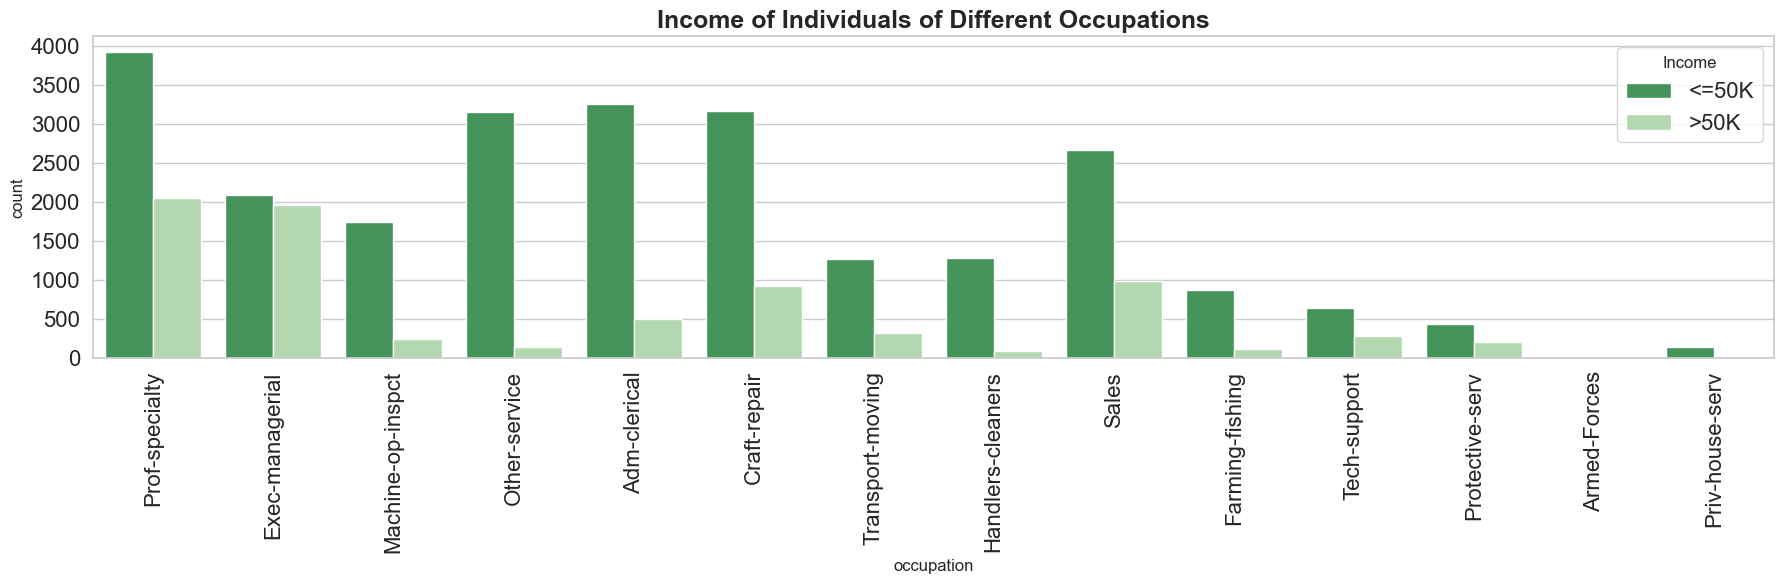

In [15]:
#income distribution across different occupations

df['occupation'] = df['occupation'].astype(str).str.strip()
df['income']     = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

plt.figure(figsize=(18,6))
sns.countplot(
    data=df,
    x='occupation',
    hue='income',
    hue_order=['<=50K', '>50K'],
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Occupations', fontsize=18, fontweight='bold')
plt.xticks(fontsize=16, rotation=90)
plt.yticks(fontsize=16)
plt.legend(title='Income', fontsize=16)
plt.tight_layout()
plt.show()


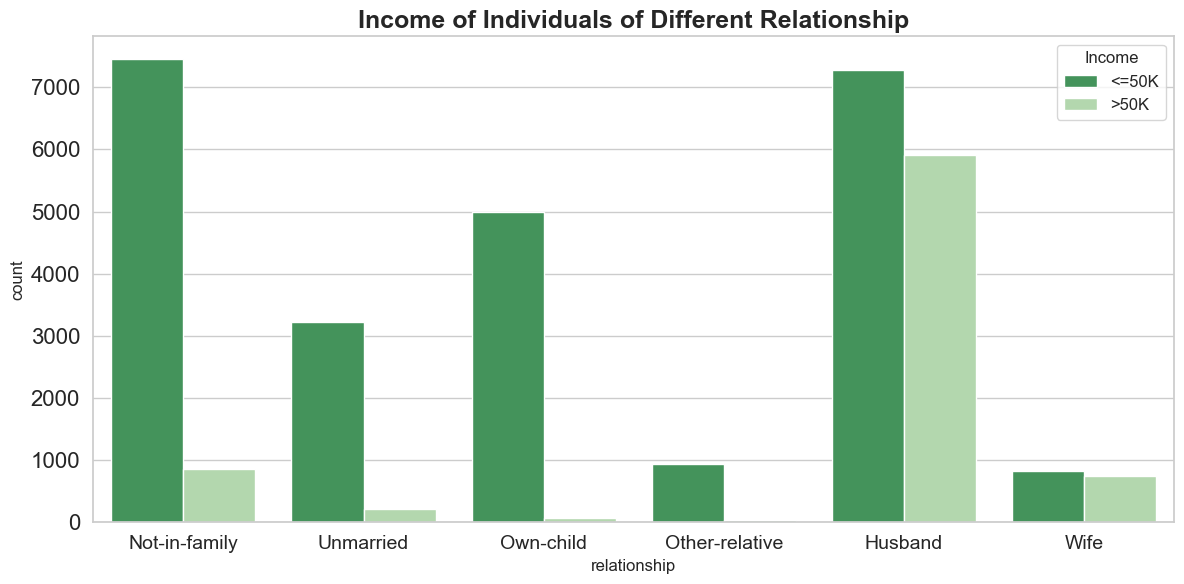

In [16]:
#income distribution across different relationship status

df['relationship'] = df['relationship'].astype(str).str.strip()
df['income'] = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x='relationship',
    hue='income',
    hue_order=['<=50K', '>50K'],
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Relationship', fontsize=18, fontweight='bold')
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=16)
plt.legend(title='Income', fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()

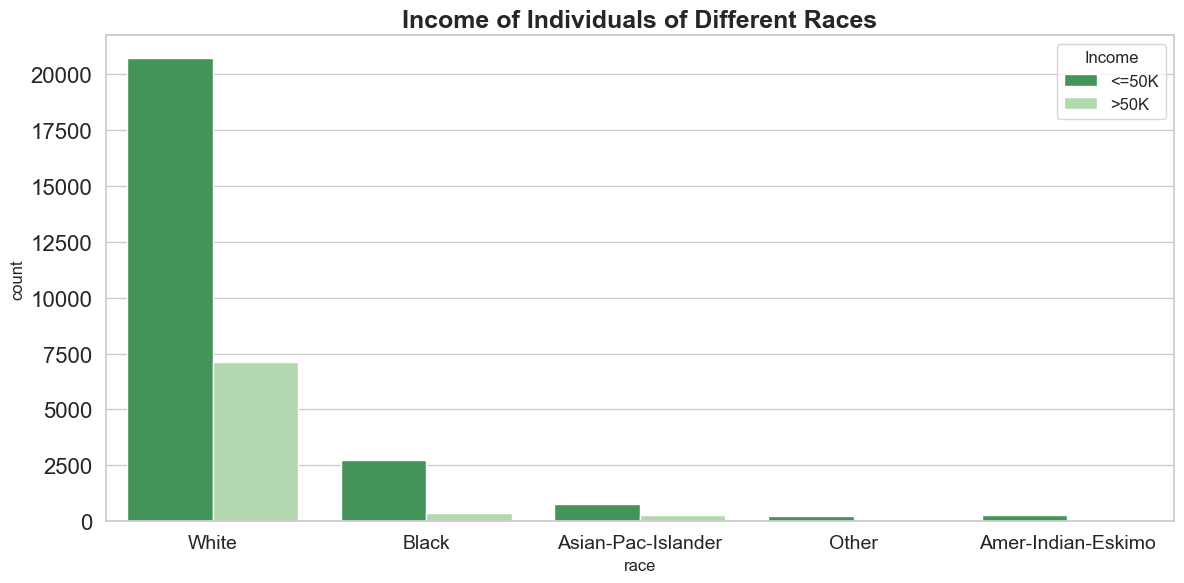

In [17]:
#income distribution across different races

df['race']   = df['race'].astype(str).str.strip()
df['income'] = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x='race',
    hue='income',
    hue_order=['<=50K','>50K'],
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Races', fontsize=18, fontweight='bold')
plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=16)
plt.legend(title='Income', fontsize=12, title_fontsize=12)
plt.tight_layout()
plt.show()

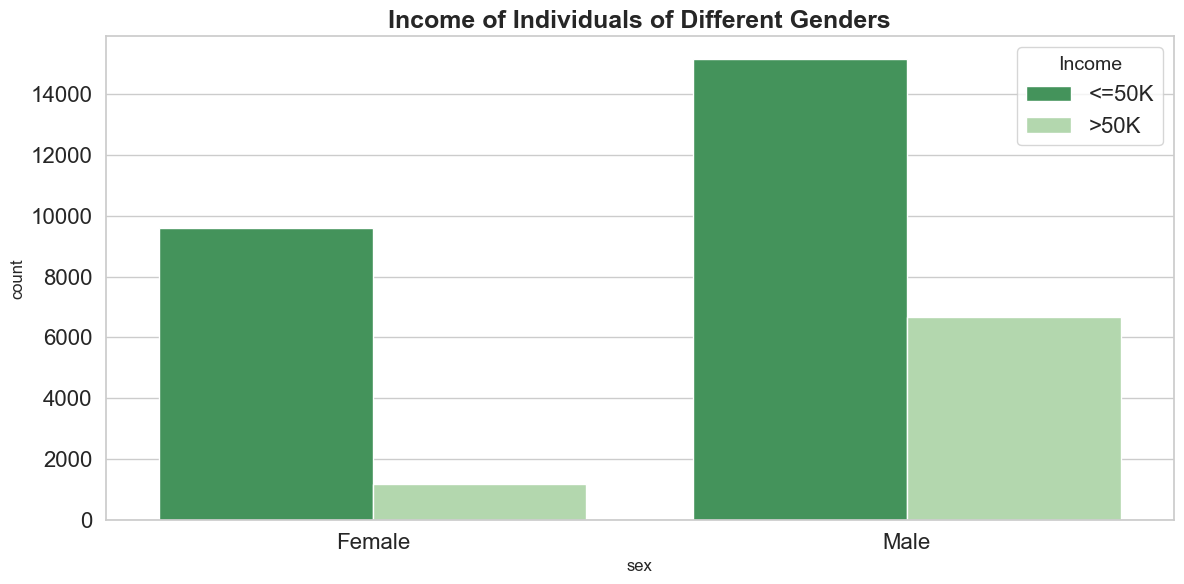

In [ ]:
# income distribution across male and female

df['sex']    = df['sex'].astype(str).str.strip()
df['income'] = df['income'].astype(str).str.strip().str.replace('.', '', regex=False)

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x='sex',
    hue='income',
    order=['Female','Male'],           
    hue_order=['<=50K','>50K'],        
    palette='Greens_r'
)
plt.title('Income of Individuals of Different Genders', fontsize=18, fontweight='bold')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.legend(title='Income', fontsize=16, title_fontsize=14)
plt.tight_layout()
plt.show()

In [19]:
df['income']=df['income'].map({'<=50K': 0, '>50K': 1})

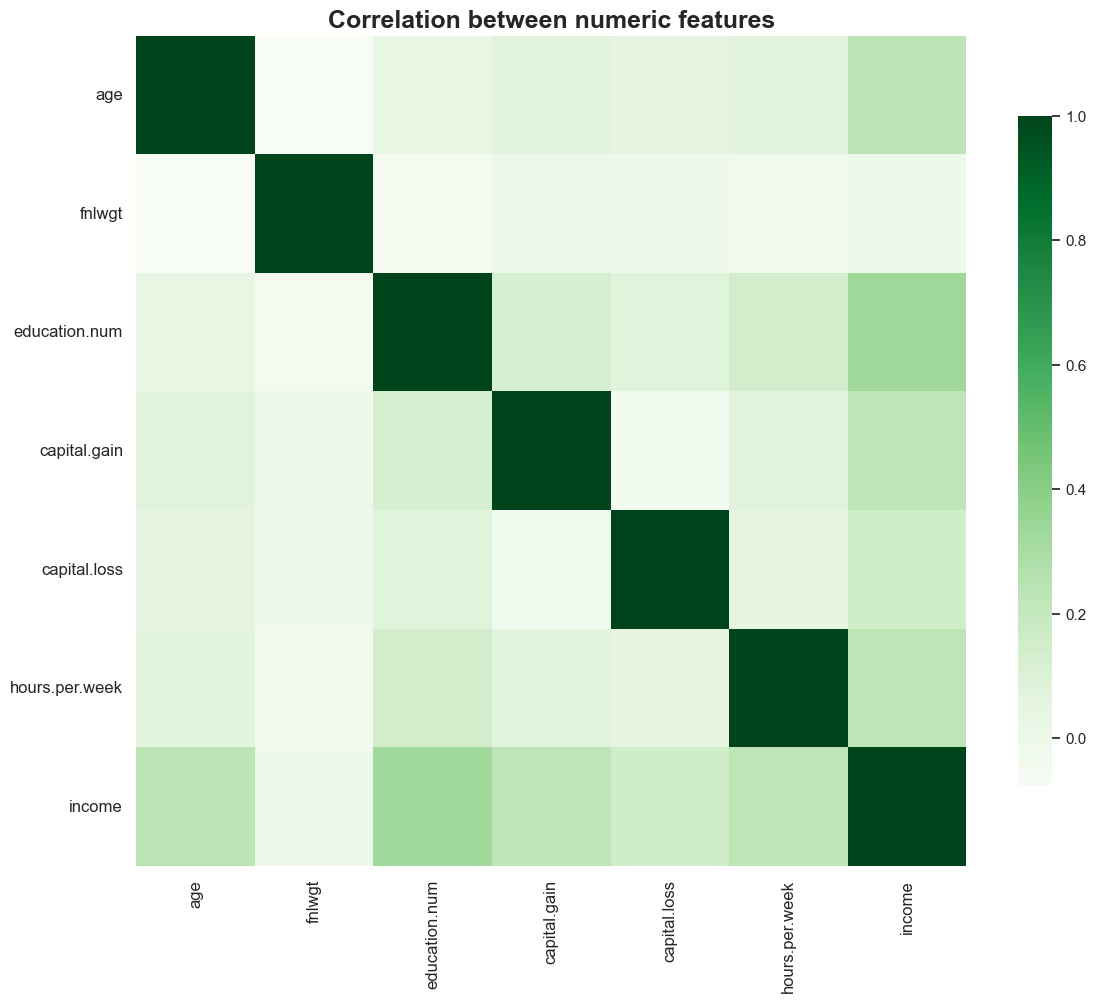

In [20]:
corr = df.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(12,10))
plt.title("Correlation between numeric features", fontsize=18, fontweight='bold')
sns.heatmap(corr, cmap='Greens', annot=False, square=True, cbar_kws={'shrink': .8})
plt.xticks(fontsize=12, rotation=90)
plt.yticks(fontsize=12, rotation=0)
plt.tight_layout()
plt.show()


In [21]:
df.drop(['education.num'], axis = 1, inplace = True)
df['education'].replace(['11th', '9th', '7th-8th', '5th-6th', '10th', '1st-4th', 'Preschool', '12th'],
                             ' School', inplace = True)

df['race'].replace(['Black', 'Asian-Pac-Islander', 'Amer-Indian-Eskimo', 'Other'],' Other', inplace = True)

In [22]:
df.drop('age_group', inplace = True, axis = 1)

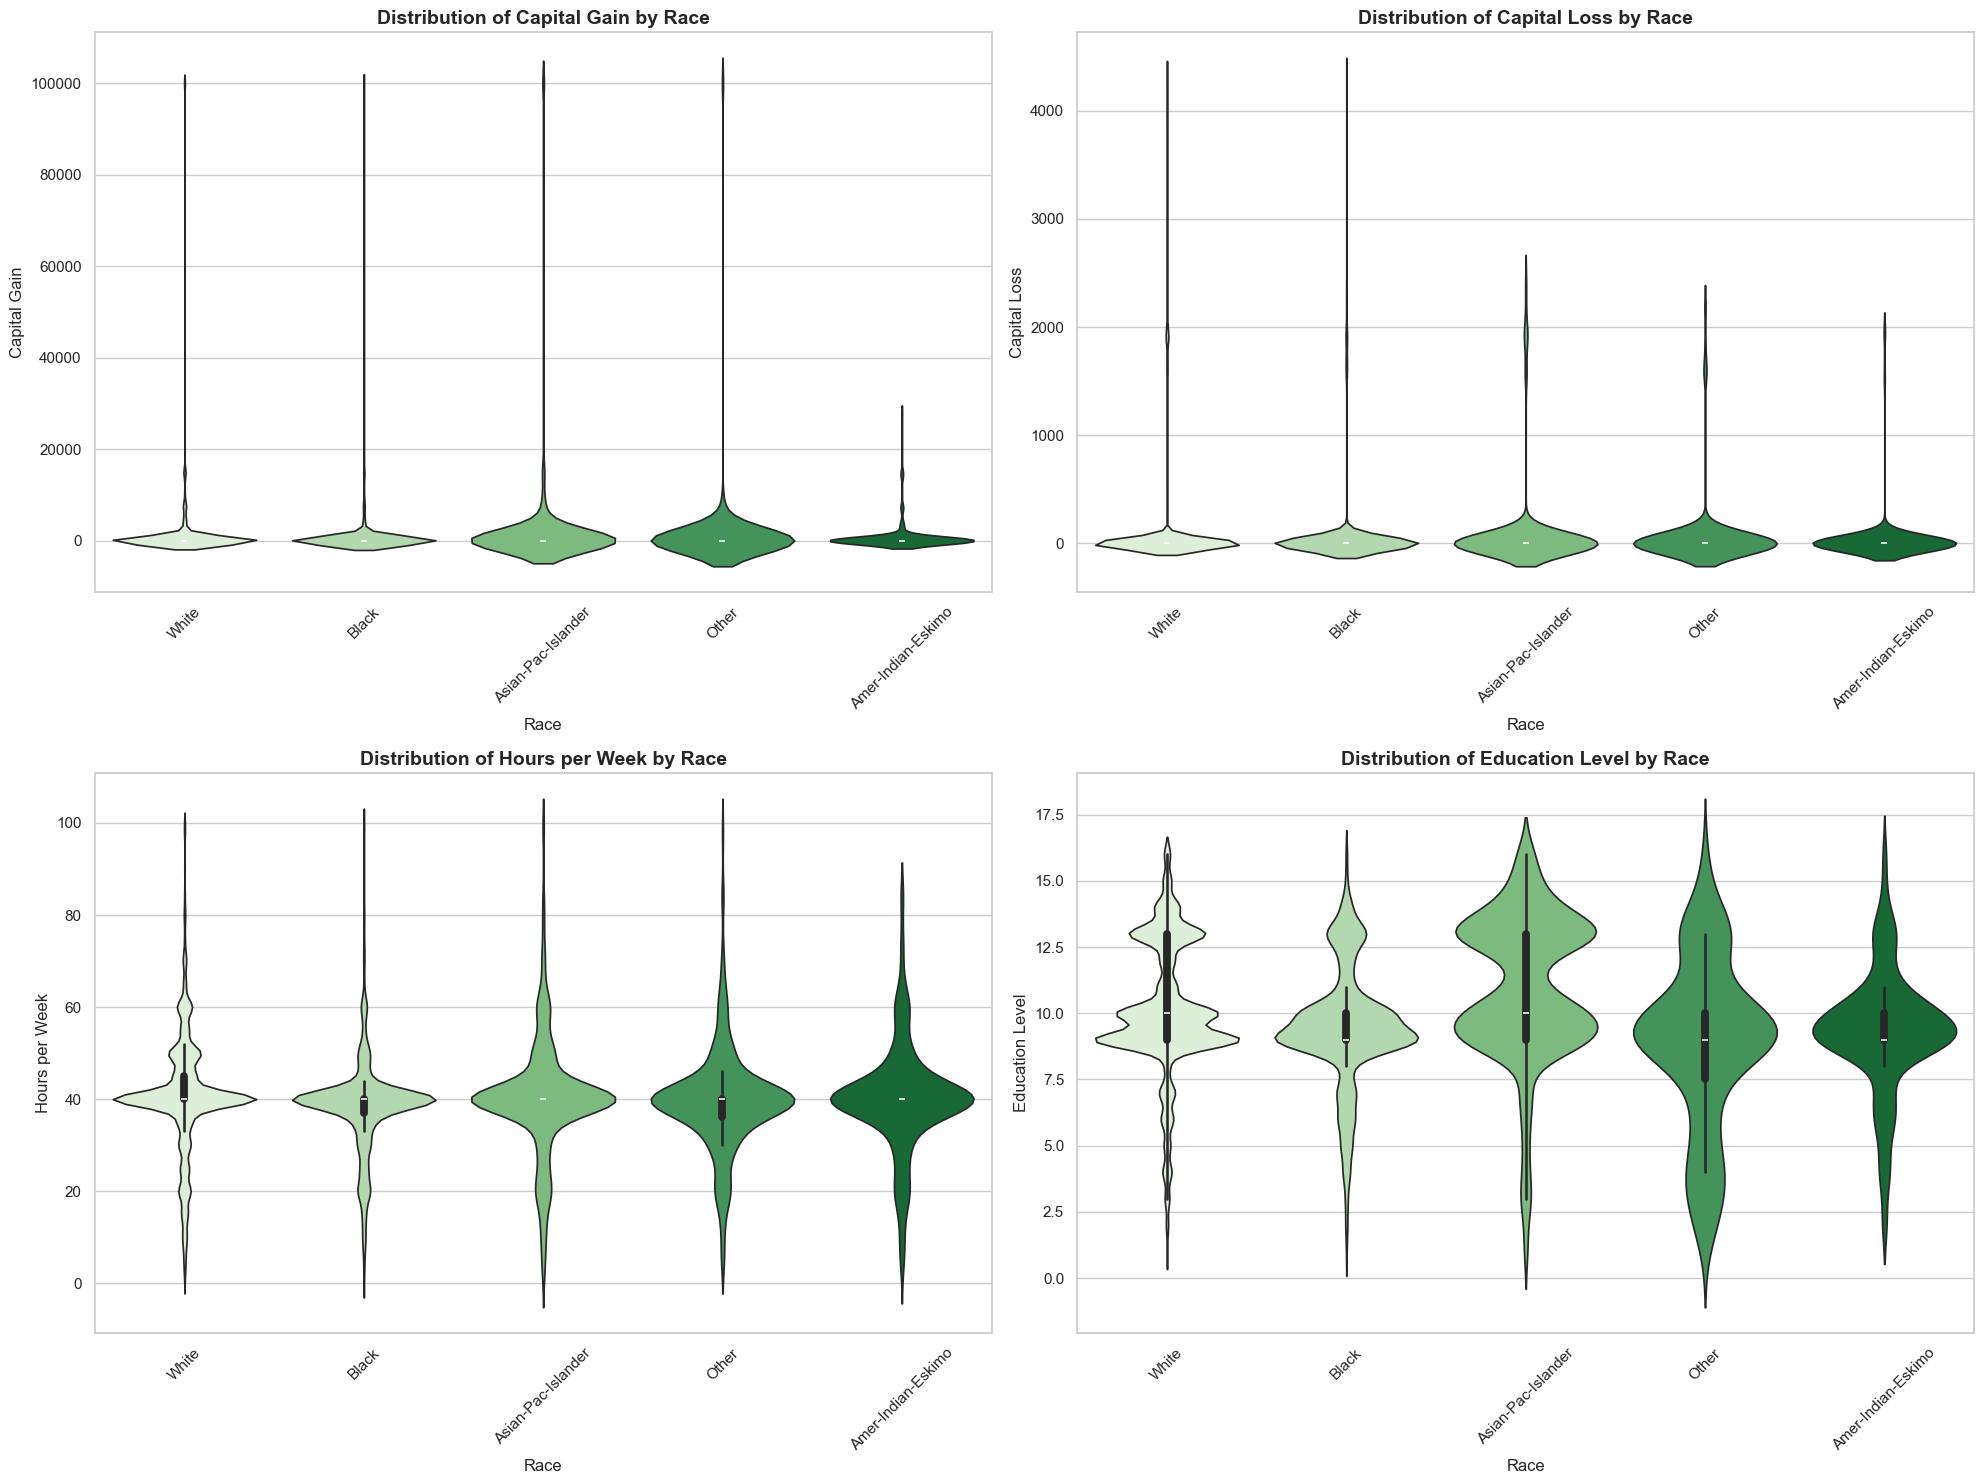

In [23]:
# Create violin plots for capital gain, loss, hours per week across races
plt.figure(figsize=(20, 15))

# Plot 1: Capital Gain by Race
plt.subplot(2, 2, 1)
sns.violinplot(data=copy1, x='race', y='capital.gain', palette='Greens')
plt.title('Distribution of Capital Gain by Race', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Race', fontsize=12)
plt.ylabel('Capital Gain', fontsize=12)

# Plot 2: Capital Loss by Race
plt.subplot(2, 2, 2)
sns.violinplot(data=copy1, x='race', y='capital.loss', palette='Greens')
plt.title('Distribution of Capital Loss by Race', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Race', fontsize=12)
plt.ylabel('Capital Loss', fontsize=12)

# Plot 3: Hours per Week by Race
plt.subplot(2, 2, 3)
sns.violinplot(data=copy1, x='race', y='hours.per.week', palette='Greens')
plt.title('Distribution of Hours per Week by Race', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Race', fontsize=12)
plt.ylabel('Hours per Week', fontsize=12)

# Plot 4: Education (using education.num) by Race
plt.subplot(2, 2, 4)
sns.violinplot(data=copy1, x='race', y='education.num', palette='Greens')
plt.title('Distribution of Education Level by Race', fontsize=14, fontweight='bold')
plt.xticks(rotation=45)
plt.xlabel('Race', fontsize=12)
plt.ylabel('Education Level', fontsize=12)

plt.tight_layout()
plt.show()

## Preprocessing 

In [24]:
df_final = copy1.copy()

In [25]:
df_final = df_final.drop_duplicates(keep = 'first')

In [26]:
df_final = df_final.reset_index(drop=True)
df_final.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,Private,77053,HS-grad,9,Widowed,Prof-specialty,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,Private,186061,Some-college,10,Widowed,Prof-specialty,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [27]:
df_final.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32537.000000,3.253700e+04,32537.000000,32537.000000,32537.000000,32537.000000
mean,38.585549,1.897808e+05,10.081815,1078.443741,87.368227,40.440329
std,13.637984,1.055565e+05,2.571633,7387.957424,403.101833,12.346889
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.369930e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [28]:
#remove unknown occupations

df_final = df_final[df_final.occupation != '?']
print (df_final['occupation'].value_counts())

occupation
Prof-specialty       5979
Craft-repair         4094
Exec-managerial      4065
Adm-clerical         3768
Sales                3650
Other-service        3291
Machine-op-inspct    2000
Transport-moving     1597
Handlers-cleaners    1369
Farming-fishing       992
Tech-support          927
Protective-serv       649
Priv-house-serv       147
Armed-Forces            9
Name: count, dtype: int64


In [29]:
# Change income column into numerical value
df_final['income'] = df_final['income'].map({'<=50K':0, '>50K':1})

In [30]:
df_final['income'].value_counts()

income
0    24698
1     7839
Name: count, dtype: int64

In [31]:
# changing categorical columns to numerical using label encoding
from sklearn.preprocessing import LabelEncoder

categorical_features = list(df_final.select_dtypes(include=['object']).columns)
label_encoder_feat = {}
for i, feature in enumerate(categorical_features):
    label_encoder_feat[feature] = LabelEncoder()
    df_final[feature] = label_encoder_feat[feature].fit_transform(df_final[feature])

df_final.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,3,77053,11,9,6,9,1,4,0,0,4356,40,38,0
1,82,3,132870,11,9,6,3,1,4,0,0,4356,18,38,0
2,66,3,186061,15,10,6,9,4,2,0,0,4356,40,38,0
3,54,3,140359,5,4,0,6,4,4,0,0,3900,40,38,0
4,41,3,264663,15,10,5,9,3,4,0,0,3900,40,38,0


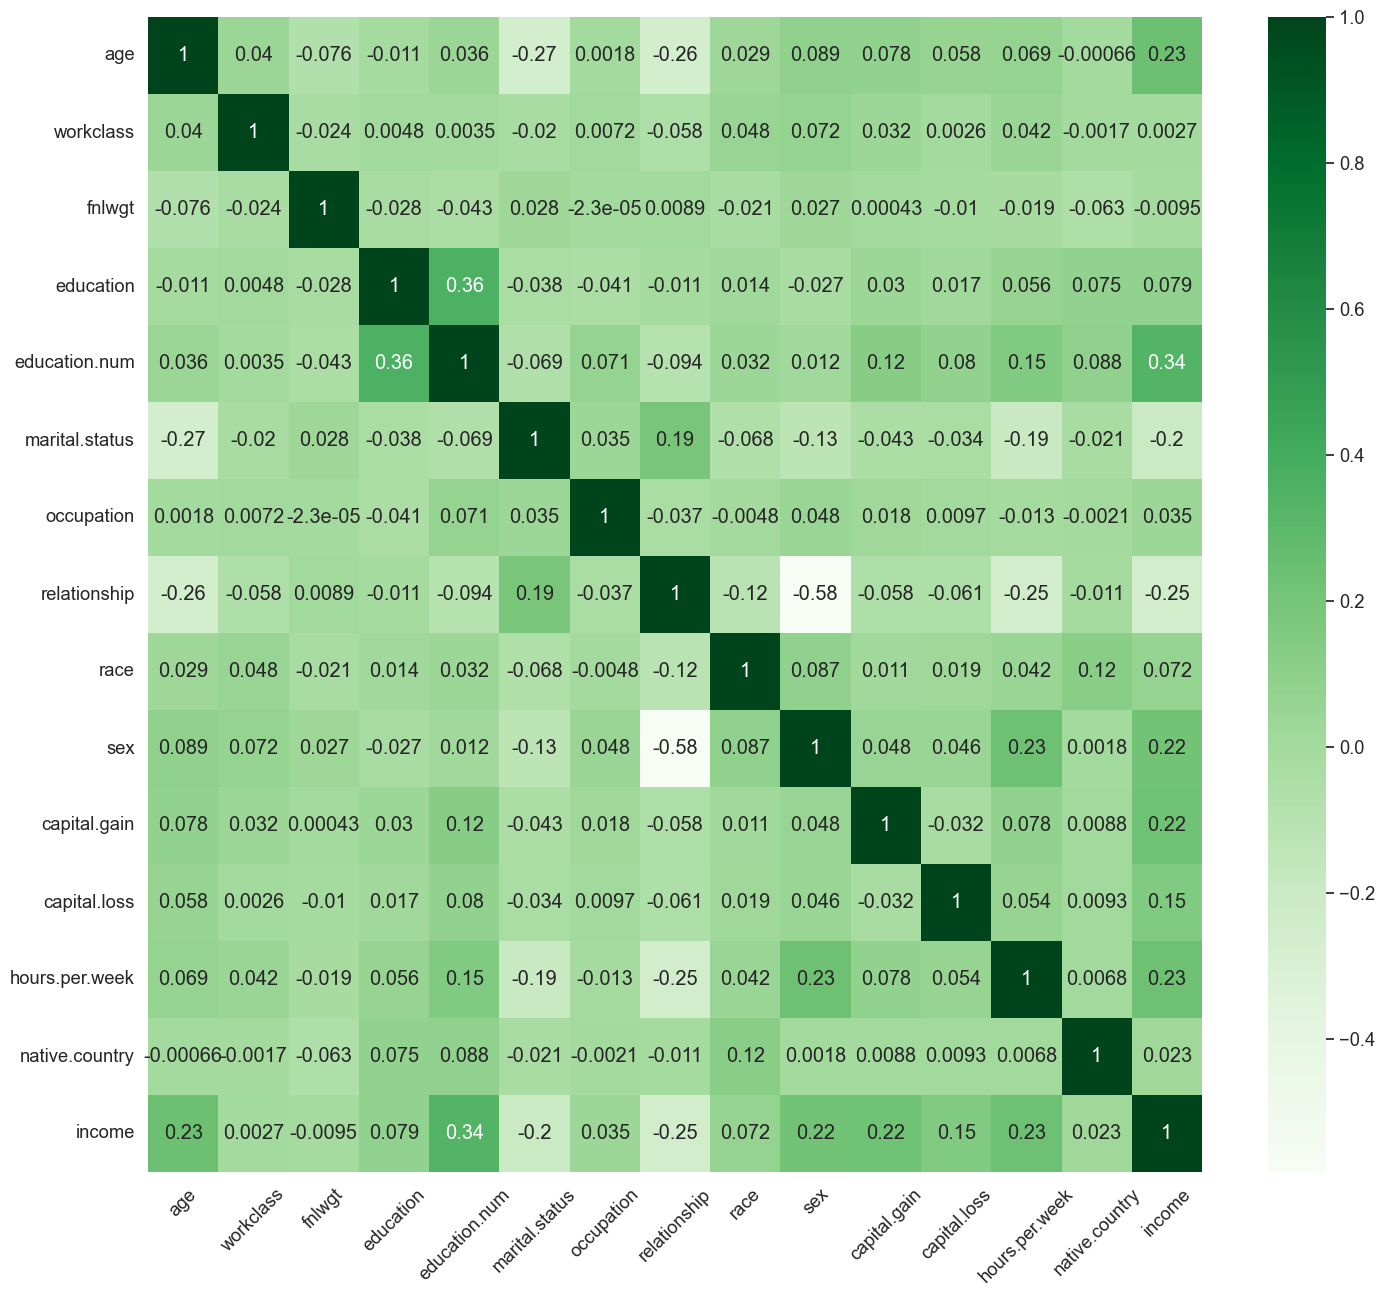

In [32]:
#Correlation heatmap
plt.rcParams['figure.figsize'] = [17,15]
sns.set(font_scale = 1.2)
corr = df_final.select_dtypes(include = 'int64').corr()
sns_ = sns.heatmap(corr, annot = True, cmap = 'Greens')
plt.setp(sns_.get_xticklabels(), rotation = 45);

In [35]:
from sklearn.model_selection import train_test_split

features_ = df_final.drop(columns=['income', 'education.num'])
target = df_final['income']
X_train, X_test, y_train, y_test = train_test_split(features_, target, test_size=0.3, random_state=0)

print("Train data set size : ", X_train.shape)
print("Test data set size : ", X_test.shape)

Train data set size :  (22775, 13)
Test data set size :  (9762, 13)


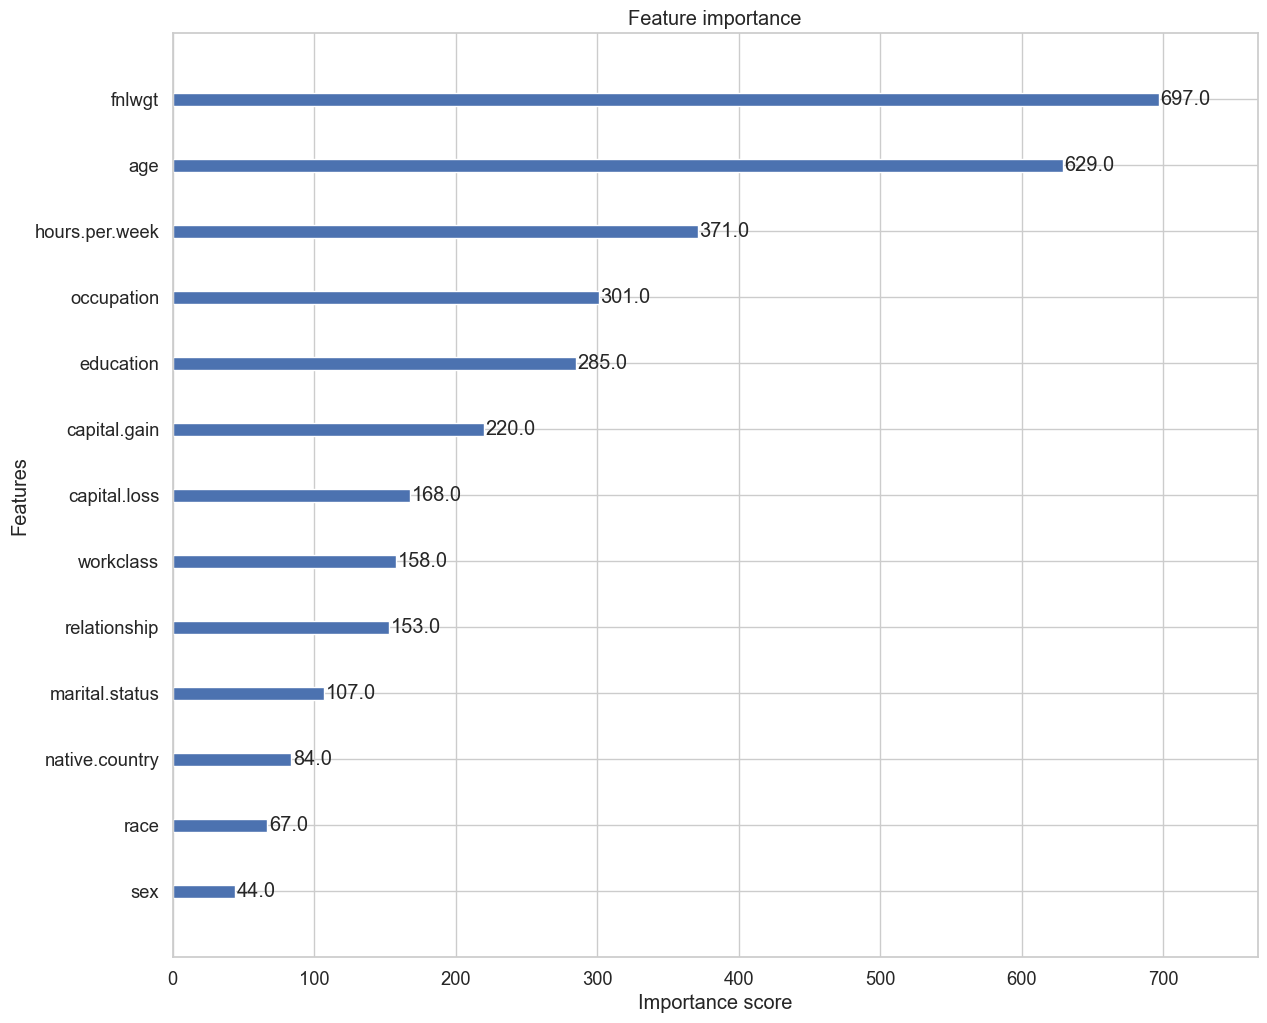

In [ ]:
import xgboost as xgb
from xgboost import XGBClassifier
from xgboost import plot_importance


model = XGBClassifier()
model_importance = model.fit(X_train, y_train)

plt.rcParams['figure.figsize'] = [14,12]
sns.set_style("whitegrid")
plot_importance(model_importance);



## Method 1: Individual Model Implementation 

## Logistic regression (baseline model)

In [ ]:
from sklearn.metrics import f1_score


logistic = LogisticRegression(C = 0.5, max_iter = 500)
model_1 = logistic.fit(X_train, y_train)


pred_1 = model_1.predict(X_test)

print (f"The accuracy of model 1 : {round(accuracy_score(y_test, pred_1) * 100, 2)} %")
print ("The f1 score of model 1 : ", round(f1_score(y_test, pred_1, average = 'binary'), 3))

The accuracy of model 1 : 79.97 %
The f1 score of model 1 :  0.418


## Random Forest Classifier

In [ ]:
from sklearn.ensemble import RandomForestClassifier

R_forest = RandomForestClassifier(n_estimators = 200)
model_2 = R_forest.fit(X_train, y_train)


pred_2 = model_2.predict(X_test)

print (f"The accuracy of model 2 : {round(accuracy_score(y_test, pred_2) * 100, 2)} %")
print ("The f1 score of model 2 : ", round(f1_score(y_test, pred_2, average = 'binary'), 3))

The accuracy of model 2 : 85.26 %
The f1 score of model 2 :  0.667


## Extreme Gradient Boosting 

In [ ]:
boosted_gd = XGBClassifier(learning_rate = 0.35, n_estimator = 500)
model_3 = boosted_gd.fit(X_train, y_train)


pred_3 = model_3.predict(X_test)

print (f"The accuracy of model 3 : {round(accuracy_score(y_test, pred_3) * 100, 2)} %")
print ("The f1 score of model 3 : ", round(f1_score(y_test, pred_3, average = 'binary'), 3))

The accuracy of model 3 : 86.36 %
The f1 score of model 3 :  0.699


## Classification Reports

In [40]:
list_pred = [pred_1, pred_2, pred_3,]
model_names = ["Logistic Regression", "Random Forest Classifier", "Boosted Gradient Descent"]

for i, predictions in enumerate(list_pred) :
    print ("Classification Report of ", model_names[i])
    print ()
    print (classification_report(y_test, predictions, target_names = ["<=50K", ">50K"]))

Classification Report of  Logistic Regression

              precision    recall  f1-score   support

       <=50K       0.81      0.96      0.88      7410
        >50K       0.70      0.30      0.42      2352

    accuracy                           0.80      9762
   macro avg       0.75      0.63      0.65      9762
weighted avg       0.78      0.80      0.77      9762

Classification Report of  Random Forest Classifier

              precision    recall  f1-score   support

       <=50K       0.88      0.93      0.91      7410
        >50K       0.73      0.61      0.67      2352

    accuracy                           0.85      9762
   macro avg       0.81      0.77      0.79      9762
weighted avg       0.85      0.85      0.85      9762

Classification Report of  Boosted Gradient Descent

              precision    recall  f1-score   support

       <=50K       0.90      0.93      0.91      7410
        >50K       0.75      0.66      0.70      2352

    accuracy                   


Logistic Regression confusion matrix (counts):
          Pred 0  Pred 1
Actual 0    7106     304
Actual 1    1651     701


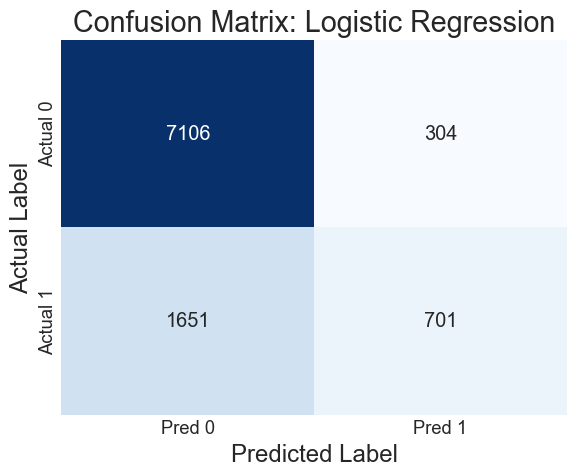


Random Forest Classifier confusion matrix (counts):
          Pred 0  Pred 1
Actual 0    6884     526
Actual 1     913    1439


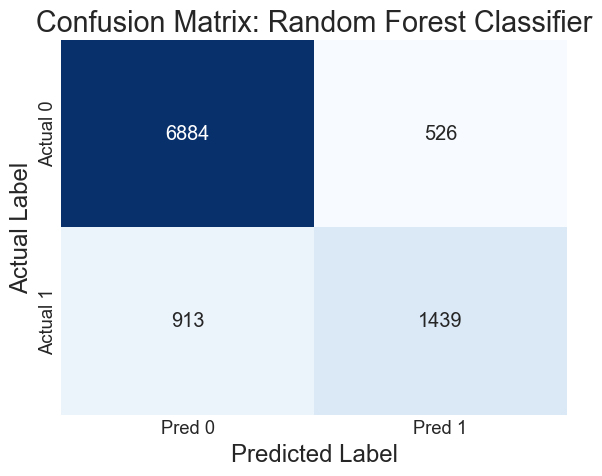


Boosted Gradient Descent confusion matrix (counts):
          Pred 0  Pred 1
Actual 0    6882     528
Actual 1     804    1548


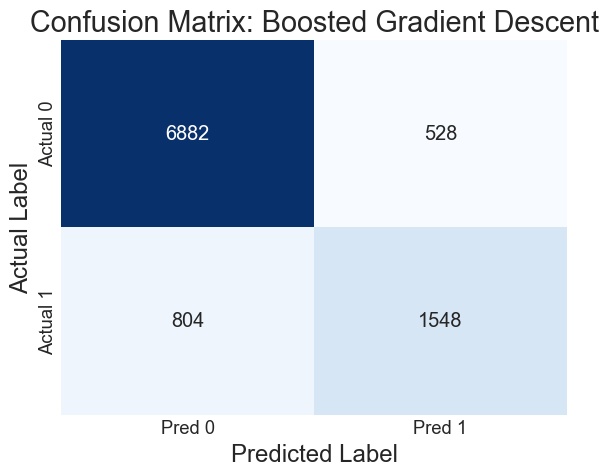

In [48]:
for name, pred in zip(model_names, list_pred):
    
    cm = confusion_matrix(y_test, pred)
    cm_df = pd.DataFrame(cm, index=["Actual 0", "Actual 1"], columns=["Pred 0", "Pred 1"])

   
    print(f"\n{name} confusion matrix (counts):")
    print(cm_df)

   
    plt.figure(figsize=(6,5))
    sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()


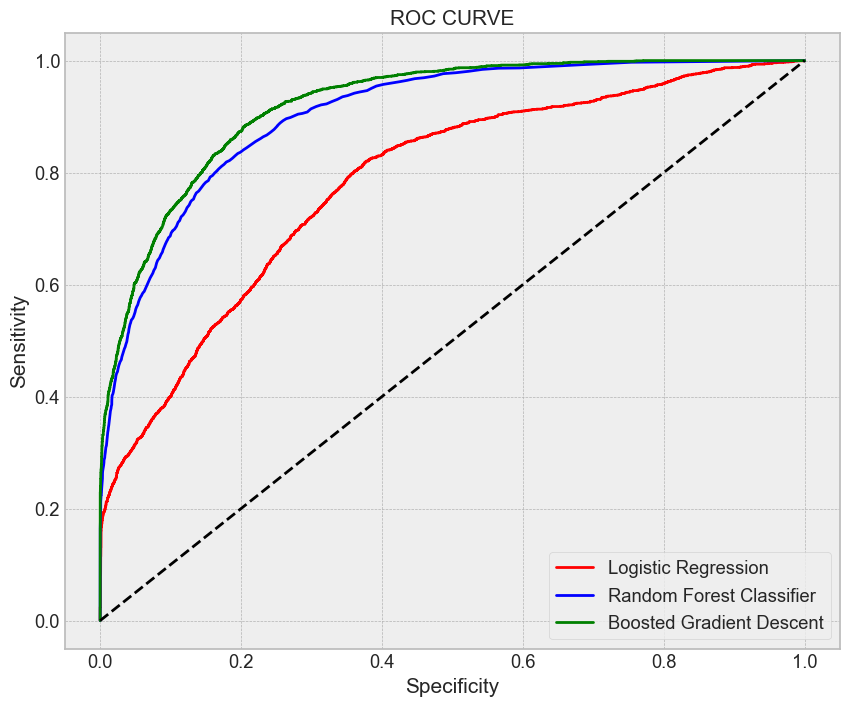

In [ ]:
from sklearn.metrics import roc_curve



models = [model_1, model_2, model_3]


plt.rcParams['figure.figsize'] = [10,8]
plt.style.use("bmh")

color = ['red', 'blue', 'green', 'fuchsia', 'cyan']
plt.title("ROC CURVE", fontsize = 15)
plt.xlabel("Specificity", fontsize = 15)
plt.ylabel("Sensitivity", fontsize = 15)
i = 1

for i, model in enumerate(models) :
    prob = model.predict_proba(X_test)
    prob_positive = prob[:,1]
    fpr, tpr, threshold = roc_curve(y_test, prob_positive)
    plt.plot(fpr, tpr, color = color[i])
    plt.gca().legend(model_names, loc = 'lower right', frameon = True)

plt.plot([0,1],[0,1], linestyle = '--', color = 'black')
plt.show()

## Method 2 : 5 Fold Cross Validation

In [43]:
## 5-fold cross validation

cv_data = copy1.copy()

cv_data['income'] = cv_data['income'].astype(str).str.strip().str.replace('.', '', regex=False)

y = (cv_data['income'] == '>50K').astype(int)
X = cv_data.drop(columns=['income'])

In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

num_cols = X.select_dtypes(include=['number']).columns.tolist()
cat_cols = X.select_dtypes(exclude=['number']).columns.tolist()

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)


cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', ohe)
])

preprocess = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
], remainder='drop')

In [45]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "RandomForest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=1),
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"roc_auc":"roc_auc","accuracy":"accuracy","precision":"precision","recall":"recall","f1":"f1"}

rows, long_rows = [], []
for name, est in models.items():
    pipe = Pipeline([('preprocess', preprocess), ('model', est)])
    cvres = cross_validate(pipe, X, y, cv=cv, scoring=scoring, n_jobs=1, return_train_score=False)

    row = {"model": name}
    for k, v in cvres.items():
        if k.startswith("test_"):
            m = k.replace("test_", "")
            row[f"{m}_mean"] = float(np.mean(v))
            row[f"{m}_std"]  = float(np.std(v))
            if m == "roc_auc":
                for s in v:
                    long_rows.append({"model": name, "score": float(s)})
    rows.append(row)

cv_summary = pd.DataFrame(rows).sort_values("roc_auc_mean", ascending=False)
cv_summary

KeyboardInterrupt: 

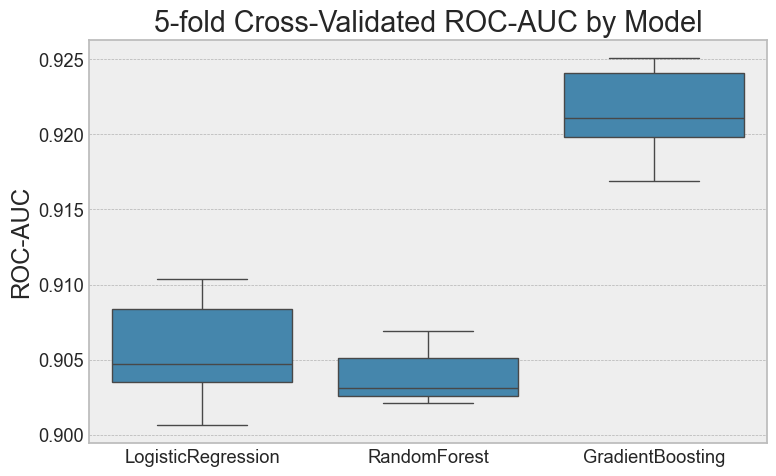

In [ ]:
import seaborn as sns, matplotlib.pyplot as plt

cv_long = pd.DataFrame(long_rows)
plt.figure(figsize=(8,5))
sns.boxplot(data=cv_long, x="model", y="score")
plt.title("5-fold Cross-Validated ROC-AUC by Model")
plt.ylabel("ROC-AUC"); plt.xlabel("")
plt.tight_layout(); plt.show()

CV winner: GradientBoosting


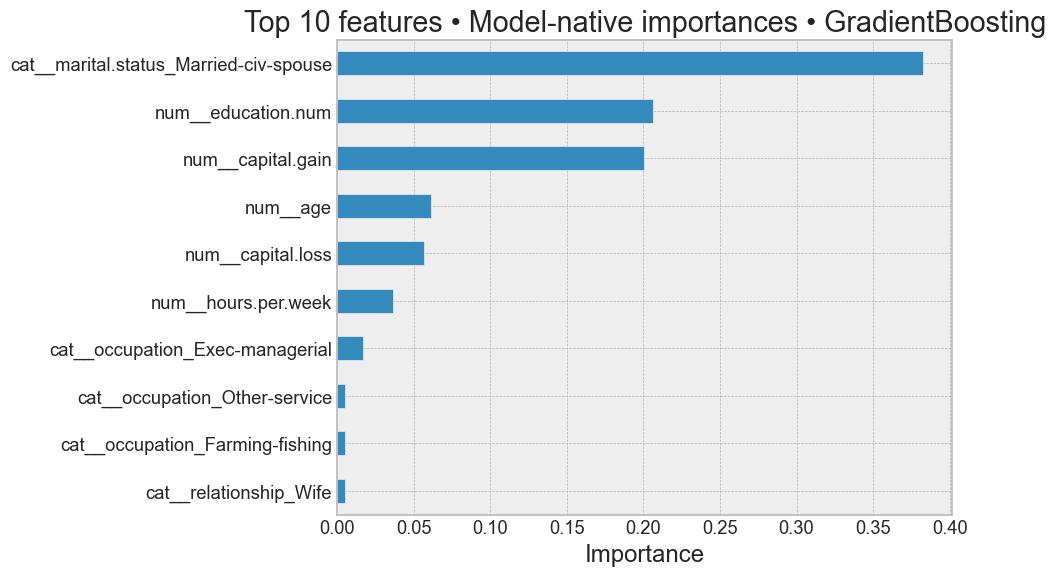

cat__marital.status_Married-civ-spouse    0.382634
num__education.num                        0.206261
num__capital.gain                         0.200630
num__age                                  0.061385
num__capital.loss                         0.056781
num__hours.per.week                       0.036216
cat__occupation_Exec-managerial           0.017046
cat__occupation_Other-service             0.005023
cat__occupation_Farming-fishing           0.004991
cat__relationship_Wife                    0.004970
dtype: float64

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from sklearn.pipeline import Pipeline

winner = cv_summary.iloc[0]["model"]
print("CV winner:", winner)

best_pipe = Pipeline([("preprocess", preprocess), ("model", models[winner])])
best_pipe.fit(X, y)

def top_features(best_pipe, X, y, k=10, scoring_name=None):
    """
    Returns (topk_series, method_used) and plots a barh chart.
    """
    preprocess = best_pipe.named_steps["preprocess"]
    model = best_pipe.named_steps["model"]
    feat_names = preprocess.get_feature_names_out()

    method = None
    scores = None

    
    if hasattr(model, "feature_importances_"):
        scores = model.feature_importances_.astype(float)
        method = "Model-native importances"

    
    elif hasattr(model, "coef_"):
        coef = model.coef_.ravel().astype(float)
        scores = np.abs(coef)
        method = "Absolute coefficients"

    if scores is None:
        from sklearn.feature_selection import mutual_info_classif
        Xt = preprocess.transform(X)
        scores = mutual_info_classif(Xt, y, discrete_features='auto', random_state=42)
        method = "Mutual information"

    s = pd.Series(scores, index=feat_names).sort_values(ascending=False)
    topk = s.head(k)

    plt.figure(figsize=(10,6))
    topk.iloc[::-1].plot(kind="barh")
    ttl = f"Top {k} features • {method} • {winner}"
    if scoring_name:
        ttl += f" (optimized for {scoring_name})"
    plt.title(ttl)
    plt.xlabel("Importance")
    plt.tight_layout()
    os.makedirs("outputs/figures", exist_ok=True)
    os.makedirs("outputs/reports", exist_ok=True)
    plt.savefig("outputs/figures/top_features.png", dpi=150)
    plt.show()
    return topk, method

top10, used = top_features(best_pipe, X, y, k=10)
top10
